# Mercury orbit Simulation

In this simulation, we want to solve the equations of motion for an N-body gravitational system, where each body interacts with every other body. (Newton's law of gravitation)

We need to solve a second-order differential equation:

$$
\frac{d^2 \vec{r}_i}{dt^2} = \sum_{\substack{j=1 \\ j \ne i}}^N G \cdot \frac{m_j (\vec{r}_j - \vec{r}_i)}{|\vec{r}_j - \vec{r}_i|^3}
$$


ri(t) is the position vector of body i, measured with respect to the Sun as the origin.

These equations form a coupled system of nonlinear ODEs, which has no analytical solution.
Therfore, we convert the system into first-order ODEs, and then use numerical integration methods to step forward in time.

In [83]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.stats import linregress
import matplotlib.pyplot as plt

### 1. Preparing all constants and parameters for the planets

In [85]:
G = 6.67430e-11            # gravutational constant  unit:m^3kg^-1s^-2
AU = 1.496e11              # Convert astronomical unit to m
day = 86400                # One day  unit:s
year = 365.25 * day        # Calendar-based average (with leap years)

In [86]:
# Define a dictionary with the parameters for the planets (mass, semi-major axis, eccentricity)
planet_data = {
    "Sun":     (1.989e30, 0, 0),
    "Mercury": (3.3e23,   0.387 * AU, 0.206),
    "Venus":   (4.87e24,  0.723 * AU, 0.007),
    "Earth":   (5.97e24,  1.000 * AU, 0.017),
    "Mars":    (6.42e23,  1.524 * AU, 0.093),
    "Jupiter": (1.90e27,  5.203 * AU, 0.049),
    "Saturn":  (5.68e26,  9.537 * AU, 0.056),
}

### 2.Define a function that returns the initial conditions of the planets
In this simulation, all planets are assumed to start at their perihelions.

Their initial velocities—corresponding to those at perihelion—are calculated using the vis-viva equation.
The vis-viva equation is given by:  
$$
v^2 = GM \left( \frac{2}{r} - \frac{1}{a} \right)
$$

Where:  
- \( v \): orbital speed at distance \( r \)  
- \( G \): gravitational constant  
- \( M \): mass of the central body (e.g., the Sun)  
- \( r \): distance from the central body at a given moment  
- \( a \): semi-major axis of the orbit

Derivation:  
The total mechanical energy \( E \) of an object in orbit is the sum of kinetic and gravitational potential energy:

$$
E = \frac{1}{2}mv^2 - \frac{GMm}{r}
$$

For elliptical orbits, the total energy is constant and equals:

$$
E = -\frac{GMm}{2a}
$$

Setting the two expressions equal and canceling mass \( m \):

$$
\frac{1}{2}v^2 - \frac{GM}{r} = -\frac{GM}{2a}
$$

Solving for \( $v^2 $\) gives the vis-viva equation:

$$
v^2 = GM \left( \frac{2}{r} - \frac{1}{a} \right)
$$

For simplicity, we operate in the center-of-mass frame and keep the center of mass fixed in space. To ensure this, the total momentum of the system must remain zero. Therefore, we adjust the Sun's velocity to balance the momentum contributed by the planets.

In [88]:
def initial_conditions(planet_names):
    states = [] # Stores the initial 2D positions and velocities of all planets
    masses = [] # Stores each planet's mass
    total_momentum = np.zeros(2)

    for planet in planet_names:
        m, a, e = planet_data[planet]
        if planet == "Sun":
            r = np.zeros(2)
            v = np.zeros(2)
        # The sun is treated as initially stationary unless corrected later.
        else:
            r = np.array([a * (1 - e), 0.0])
            M_sun = planet_data["Sun"][0]
            v_mag = np.sqrt(G * M_sun * (2 / np.linalg.norm(r) - 1 / a))  # the vis-viva equation
            v = np.array([0.0, v_mag])
            total_momentum += m * v # Adds this planet's momentum to the cumulative total momentum of all planets processed so far.
        states.extend(r)
        states.extend(v)
        masses.append(m)

    if "Sun" in planet_names:
        sun_index = planet_names.index("Sun")
        sun_mass = planet_data["Sun"][0]
        v_sun = -total_momentum / sun_mass # Computes the Sun's velocity needed to cancel out the total momentum of all other planets.
        states[4*sun_index+2:4*sun_index+4] = v_sun # Inserts the computed v_sun into the right location

    return np.array(states), np.array(masses)

### 3. Define a function that computes the derivative of the position and velocity of all bodies in the system
Formula for the gravitational acceleration:
$$
\vec{a}_i = \sum_j \frac{G m_j (\vec{r}_j - \vec{r}_i)}{|\vec{r}_j - \vec{r}_i|^3}
$$

In [90]:
def nbody_deriv(t, y, masses): # t is the current time, y is the current state vector (containing all positions and velocities)
    N = len(masses)
    dydt = np.zeros_like(y) # Creates a new NumPy array filled with zeros that has the same shape and data type as y, and it will store the time derivatives of position and velocity
    for i in range(N):
        ri = y[4*i:4*i+2] # # Extracts the position vector [x, y] of the i-th planet
        vi = y[4*i+2:4*i+4]
        ai = np.zeros(2) # To hold the total gravitational acceleration acting on body i due to all other bodies
        for j in range(N):
            if i == j:
                continue # Skip the iteration when a planet is trying to compute its gravitational interaction with itself
            rj = y[4*j:4*j+2] # Extracts the position vector [x, y] of the j-th planet
            r_vec = rj - ri
            rnorm = np.linalg.norm(r_vec) # Computes the magnitude of the distance between the two planets
            ai += G * masses[j] * r_vec / (rnorm**3)
        dydt[4*i:4*i+2] = vi
        dydt[4*i+2:4*i+4] = ai
    return dydt
# The function finally sets the full derivative vector (dydt) for the numerical integrator

### 4. Define a function that calculates the argument of perihelion over time

In [92]:
def compute_argument_of_perihelion(positions):
    x, y = positions[:, 0], positions[:, 1] # Extracts the x and y coordinate arrays from the positions array
    r = np.sqrt(x**2 + y**2) # Compute the distance between Mercury and the Sun for each point in the simulation
    peri_indices = np.where((r[1:-1] < r[:-2]) & (r[1:-1] < r[2:]))[0] + 1 # FInds the indicies of the local minima in r (the perihelion)
    peri_vectors = positions[peri_indices] # Selects the position vectors corresponding to the perihelion identified above.
    angles = np.arctan2(peri_vectors[:, 1], peri_vectors[:, 0])
    angles = np.unwrap(angles) # Remove discontinuities 
    return angles, peri_indices # peri_indices: the time indices corresponding to each perihelion

### 5. Define a function that simulates the orbital motion of the planets
In thsi simulation, we use solve_ivp as the numerical integrator.

In [94]:
def run_simulation(planet_list, total_years=800):  
    y0, masses = initial_conditions(planet_list) # y0: the initial state vector
    t_span = (0, total_years * year)
    t_eval = np.linspace(*t_span, total_years * 200) # Samples 200 points per year to get smooth results

    sol = solve_ivp(nbody_deriv, t_span, y0, t_eval=t_eval, args=(masses,),
                    rtol=1e-12, atol=1e-12, method='DOP853')

    sun_idx = planet_list.index("Sun")
    mercury_idx = planet_list.index("Mercury")
    # Finds the index of the Sun and Mercury in the input list. This is used to extract their position data from the full solution array.
    
    sun_pos = sol.y[4*sun_idx:4*sun_idx+2].T # Extracts the x and y positions of the Sun over time.
    mercury_abs = sol.y[4*mercury_idx:4*mercury_idx+2].T # Extracts Mercury’s absolute position in space over time.
    mercury_pos = mercury_abs - sun_pos  

    angles, peri_indices = compute_argument_of_perihelion(mercury_pos)
  
    times = np.array(peri_indices) * (t_span[1] / len(t_eval)) # Converts the indices of perihelion into actual times (in seconds).

    slope, _, _, _, _ = linregress(times, angles)

    precession_rate = slope * (100 * year) * (180 / np.pi) * 3600  # Convert the slope from radians per second to arcseconds per century
    
    return precession_rate, angles, peri_indices, mercury_pos

### 6.Add each planet and run the simulation

In [96]:
sets = [
    ["Sun", "Mercury"],
    ["Sun", "Mercury", "Venus"],
    ["Sun", "Mercury", "Venus", "Earth"],
    ["Sun", "Mercury", "Venus", "Earth", "Mars"],
    ["Sun", "Mercury", "Venus", "Earth", "Mars", "Jupiter"],
    ["Sun", "Mercury", "Venus", "Earth", "Mars", "Jupiter", "Saturn"]
] # The contributions from Uranus and Neptune are very small, so we ignore them in this simulation

for s in sets:
    rate, *_ = run_simulation(s)
    print(f"{' + '.join(s):<60}: {rate:.2f} arcsec/century")

Sun + Mercury                                               : 7.44 arcsec/century
Sun + Mercury + Venus                                       : 292.67 arcsec/century
Sun + Mercury + Venus + Earth                               : 381.17 arcsec/century
Sun + Mercury + Venus + Earth + Mars                        : 376.65 arcsec/century
Sun + Mercury + Venus + Earth + Mars + Jupiter              : 520.54 arcsec/century
Sun + Mercury + Venus + Earth + Mars + Jupiter + Saturn     : 528.05 arcsec/century


Result:
Sun + Mercury                                               : 7.44 arcsec/century  
Sun + Mercury + Venus                                       : 292.67 arcsec/century  
Sun + Mercury + Venus + Earth                               : 381.17 arcsec/century 
Sun + Mercury + Venus + Earth + Mars                        : 376.65 arcsec/century  
Sun + Mercury + Venus + Earth + Mars + Jupiter              : 520.54 arcsec/century  
Sun + Mercury + Venus + Earth + Mars + Jupiter + Saturn     : 528.05 arcsec/century  

### Validity and Interpretation of Simulated Perihelion Precession
The precession rates obtained from the numerical simulation show a gradual increase as more planetary bodies are included, ultimately approaching the expected theoretical value of approximately 531 arcseconds per century. While there are slight fluctuations—such as a decrease after adding Mars—these variations are natural and reasonable in the context of numerical N-body simulations.

These small deviations can be attributed to several factors:

1. Numerical sensitivity: N-body simulations are sensitive to initial conditions, integration step sizes, and round-off errors, especially when simulating over long timescales like 800 years.

2. Interference effects: The gravitational influence of each planet does not simply add linearly. Interactions between planets (e.g., Venus and Earth) can interfere constructively or destructively, slightly altering the total precession.

3. Orbital resonances and timing: The positions and velocities of planets vary cyclically. At certain times, their combined gravitational influence on Mercury may be stronger or weaker depending on alignment and relative phases.

Overall, the trend and final value (~528 arcsec/century) indicate that the simulation is capturing the essential physics accurately. Minor differences from the ideal 531 arcseconds are expected and acceptable in practical numerical computations.

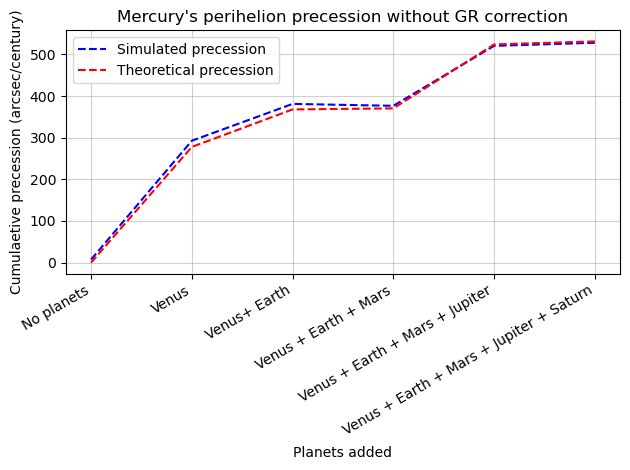

In [135]:
planet_number = np.array([0, 1, 2, 3, 4, 5])
total_precession = np.array([7.44, 292.67, 381.17, 376.6, 520.54, 528.05])
total_precession_theo  = np.array([0, 277.856, 367.894, 370.447, 524.031, 531.333])

plt.figure()
plt.grid(alpha = 0.6)
plt.title("Mercury's perihelion precession without GR correction")
plt.plot(planet_number, total_precession, linestyle = '--', color = 'blue', label = 'Simulated precession')
plt.plot(planet_number, total_precession_theo, linestyle = '--', color = 'red', label = 'Theoretical precession')
plt.xlabel('Planets added')
plt.ylabel('Cumulaetive precession (arcsec/century)')
plt.xticks([0, 1, 2, 3, 4, 5], ['No planets', 'Venus', 'Venus+ Earth', 'Venus + Earth + Mars', 'Venus + Earth + Mars + Jupiter', ' Venus + Earth + Mars + Jupiter + Saturn'], rotation = 30, ha='right')
plt.tight_layout()
plt.legend()
plt.savefig('Simulated precession plot.png', dpi = 300)
plt.show()